# 356. Does a search call land on one exon's residues? (midi-plus, chicken and zebrafish)

**Question.** A human query protein is searched against chicken or zebrafish. When a tool
calls a region of the target protein, does that call sit on the residues one exon codes,
or does it spread over the whole protein? Notebook
[244](https://github.com/seanome/2024-kmerseek-analysis/pull/49) asked this with short
Swiss-Prot features as the truth: kmerseek's call landed on 176 of 182 features, Foldseek
on 2 and ProstT5 on 3. Here the truth is the target protein's exons.

**What decision this informs.** If kmerseek lands on short exons and structure tools do
not, the paper can say that kmerseek places a match on a single exon, which structure
search cannot. If it fails, the exon claim stays out of the paper, and nb 244's result is
about Swiss-Prot features only.

**Words.** A call *lands* on an exon when at least 80% of the call is inside the exon and
the call covers at least 30% of the exon (nb 244's rule). It *spills* when less than half
of the call is inside the exon. *Partial*: it overlaps the exon with at least half of
itself inside, but does not land. *No call*: no call between the two proteins touches the
exon. IoU is the overlap of the call and the exon divided by their union.

**Decision rule, written before the run**
([preregistered.md](356_data/preregistered.md), with its 2026-10-20 amendments). On
internal coding exons of 60 residues or fewer, on pairs where both proteins have an
AlphaFold model:

1. kmerseek (best of all settings) lands on at least 50% of them;
2. every structure tool (Foldseek, Reseek, ProstT5) lands on under 15%;
3. kmerseek's landing rate, counting only calls whose placement p-value is below 0.05,
   is at least twice the Kyte-Doolittle scan's.

Pass needs all three. Stop 0 also stops the work if kmerseek lands on under 10% of short
exons, or if the Kyte-Doolittle scan lands as often as kmerseek (then the result is about
amino-acid composition, not search).

**Data.** The midi-plus run (1-8 Sept 2026): 998 human queries (chromosome 6, plus B2M,
CD1A-E, MR1, KIR and LILR) searched against the nine QfO 2020_04 proteomes, image
`olgabot/kmerseek:2026-08-24-reduced-alphabets`. Query = human; target database = the
chicken (UP000000539) or zebrafish (UP000000437) proteome. Only calls between a query and
its 1:1 OMA ortholog are scored. kmerseek calls are kept at Bonferroni p < 0.05, as in
nb 244. Exons come from UniProt's exon map for the same protein sequences (the QfO
release's `_gcoord.xml`).

In [1]:
import json
import sys
from pathlib import Path

import polars as pl

sys.path.insert(0, str(Path.cwd()))
import exon_landing_356 as el

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(200)
STAGE = "pilot"
TABLES = Path("../tables/356/pilot")
FIG = Path("../figures/356/pilot")
d = el.load(TABLES)
v = d["verdict"]
inputs = json.loads(Path("356_data/exon_inputs.json").read_text())
et = d["exon_tool"]
one_tool = et.filter(pl.col("tool") == "kmerseek_best_of_all")
print(f"stage: {v['stage']}; pairs scored: {v['n_pairs']}")
print(
    one_tool.group_by("species").agg(
        pairs=pl.struct("query_acc", "target_acc").n_unique(),
        exons=pl.len(),
        internal=pl.col("internal").sum(),
        internal_le60=pl.col("short_internal").sum(),
        both_models=pl.col("both_models").sum(),
        verdict_exons=pl.col("verdict_set").sum(),
    )
)

stage: pilot, 200 pairs; pairs scored: 200
shape: (2, 7)
┌───────────┬───────┬───────┬──────────┬───────────────┬─────────────┬───────────────┐
│ species   ┆ pairs ┆ exons ┆ internal ┆ internal_le60 ┆ both_models ┆ verdict_exons │
│ ---       ┆ ---   ┆ ---   ┆ ---      ┆ ---           ┆ ---         ┆ ---           │
│ str       ┆ u32   ┆ u32   ┆ u32      ┆ u32           ┆ u32         ┆ u32           │
╞═══════════╪═══════╪═══════╪══════════╪═══════════════╪═════════════╪═══════════════╡
│ chicken   ┆ 72    ┆ 641   ┆ 502      ┆ 412           ┆ 300         ┆ 198           │
│ zebrafish ┆ 126   ┆ 1009  ┆ 769      ┆ 629           ┆ 671         ┆ 416           │
└───────────┴───────┴───────┴──────────┴───────────────┴─────────────┴───────────────┘


## 1. Verdict against the pre-registered rules

Each row is one rule with the count behind it. Higher landing is better for kmerseek; for
structure tools the rule asks for low landing, because nb 244 found that they cover the
whole protein.

shape: (6, 5)
┌─────────────────────────────────┬────────┬─────────┬───────┬──────┐
│ rule                            ┆ n_land ┆ n_exons ┆ rate  ┆ pass │
│ ---                             ┆ ---    ┆ ---     ┆ ---   ┆ ---  │
│ str                             ┆ i64    ┆ i64     ┆ f64   ┆ bool │
╞═════════════════════════════════╪════════╪═════════╪═══════╪══════╡
│ 1: kmerseek best of all lands … ┆ 416    ┆ 614     ┆ 0.678 ┆ true │
│ 2: foldseek lands < 15%         ┆ 0      ┆ 614     ┆ 0.0   ┆ true │
│ 2: reseek lands < 15%           ┆ 0      ┆ 614     ┆ 0.0   ┆ true │
│ 2: prostt5 lands < 15%          ┆ 0      ┆ 614     ┆ 0.0   ┆ true │
│ 3: kmerseek lands with p_place… ┆ 237    ┆ 614     ┆ 0.386 ┆ null │
│ 3: Kyte-Doolittle scan lands    ┆ 35     ┆ 614     ┆ 0.057 ┆ null │
└─────────────────────────────────┴────────┴─────────┴───────┴──────┘
rule 3 ratio (kmerseek / scan): 6.771428571428572; pass: True
random-protein null of kmerseek's best of all: median 0.637, 99.9th percentile 0.697

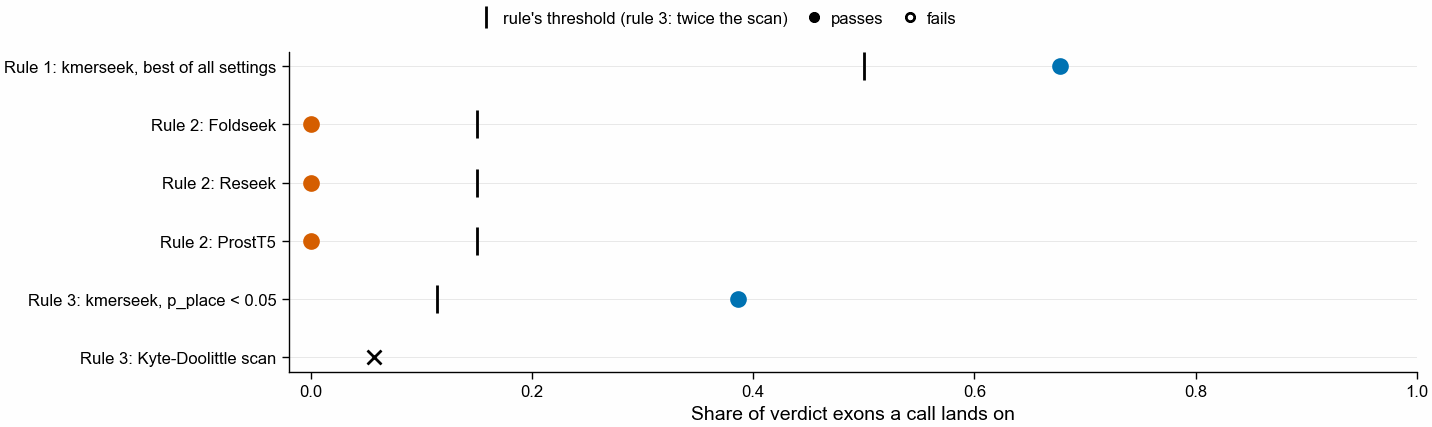

In [2]:
rows = [
    (
        "1: kmerseek best of all lands >= 50%",
        *v["rule_1"]["kmerseek_best_of_all_lands"],
        v["rule_1"]["pass"],
    ),
    *[
        (f"2: {t} lands < 15%", *x, x[2] is not None and x[2] < 0.15)
        for t, x in v["rule_2"]["structure_tools_land"].items()
    ],
    (
        "3: kmerseek lands with p_place < 0.05",
        *v["rule_3"]["kmerseek_lands_with_p_place_lt_0.05"],
        None,
    ),
    ("3: Kyte-Doolittle scan lands", *v["rule_3"]["kd_scan_lands"], None),
]
verdict_tab = pl.DataFrame(
    rows, schema=["rule", "n_land", "n_exons", "rate", "pass"], orient="row"
)
print(verdict_tab.with_columns(pl.col("rate").round(3)))
print(
    f"rule 3 ratio (kmerseek / scan): {v['rule_3']['ratio']}; pass: {v['rule_3']['pass']}"
)
print(
    f"random-protein null of kmerseek's best of all: median {v['random_protein_null']['median']:.3f}, "
    f"99.9th percentile {v['random_protein_null']['quantile_0.999']:.3f}; "
    f"observed above it: {v['random_protein_null']['observed_above_0.999']}"
)
print(
    f"Stop 0 empty question (kmerseek < 10%): {v['empty_question_kmerseek_below_0.10']}"
)
print(
    f"Stop 0 kill condition (scan at kmerseek's rate): {v['kill_condition_kd_at_kmerseek_rate']}"
)
print(f"OVERALL PASS: {v['pass']}")
vfig = el.verdict_figure(d, FIG / "356_verdict_rules_midi_plus_chicken_zebrafish")

## 2. Landing rate by exon length (Figure 1)

How to read it: each line is one tool; a point is the share of exons in that length bin
that some call of the tool lands on. The grey band is the exons the rules use. A tool
that places calls on single exons sits high on the left; a tool whose calls cover whole
proteins sits near zero everywhere except, perhaps, the longest exons.

shape: (11, 6)
┌──────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ tool                 ┆ <=20     ┆ 21-40    ┆ 41-60    ┆ 61-120   ┆ >120     │
│ ---                  ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str                  ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞══════════════════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ foldseek             ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0      │
│ hhblits              ┆ 0.0      ┆ 0.036184 ┆ 0.066148 ┆ 0.04717  ┆ 0.055556 │
│ hmmer3_jackhmmer     ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0      │
│ hmmer3_phmmer        ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.055556 │
│ kd_scan              ┆ 0.0      ┆ 0.049342 ┆ 0.077821 ┆ 0.066038 ┆ 0.0      │
│ kmerseek_best_of_all ┆ 0.283019 ┆ 0.651316 ┆ 0.789883 ┆ 0.688679 ┆ 0.333333 │
│ kmerseek_best_single ┆ 0.075472 ┆ 0.378289 ┆ 0.29572  ┆ 0.160377 ┆ 0.055556 │
│ mmseqs2_iterative    ┆ 

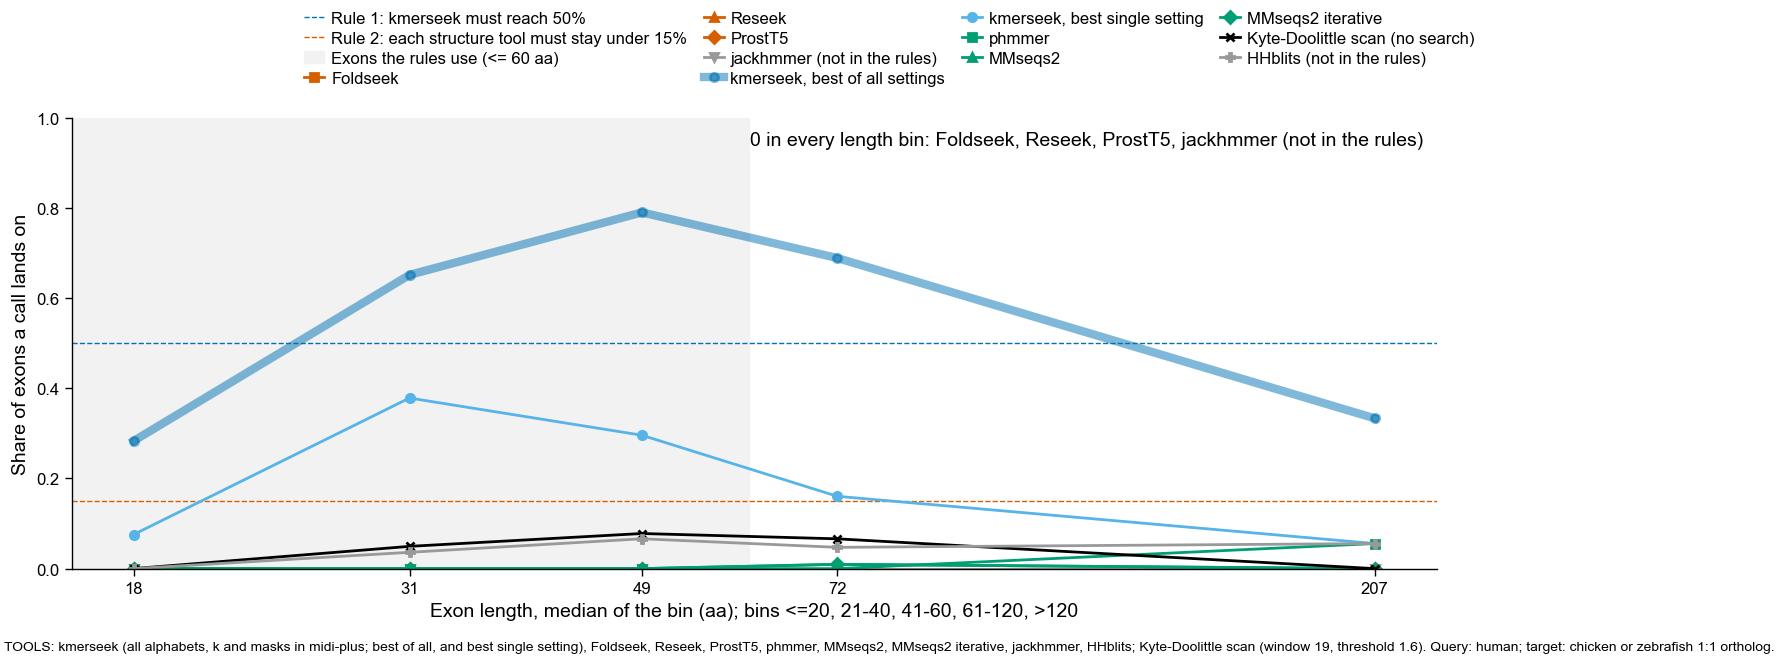

In [3]:
tools_line = (
    "TOOLS: kmerseek (all alphabets, k and masks in midi-plus; best of all, and best single setting), "
    "Foldseek, Reseek, ProstT5, phmmer, MMseqs2, MMseqs2 iterative, jackhmmer, HHblits; "
    "Kyte-Doolittle scan (window 19, threshold 1.6). Query: human; target: chicken or zebrafish 1:1 ortholog."
)
fig1 = el.landing_by_length(
    d, FIG / "356_fig1_landing_by_exon_length_midi_plus_chicken_zebrafish", tools_line
)
print(
    fig1.pivot(on="length_bin", index="tool", values="rate").select(
        "tool", *[b for b in el.BIN_ORDER if b in fig1["length_bin"].unique()]
    )
)

## 3. What each tool's call does on the short exons (SF2)

For each tool, the verdict exons split by outcome: lands, partial, spills, no call.

shape: (11, 6)
┌──────────────────────┬───────┬─────────┬────────┬─────────┬─────┐
│ tool                 ┆ lands ┆ partial ┆ spills ┆ no call ┆ n   │
│ ---                  ┆ ---   ┆ ---     ┆ ---    ┆ ---     ┆ --- │
│ str                  ┆ u32   ┆ u32     ┆ u32    ┆ u32     ┆ u32 │
╞══════════════════════╪═══════╪═════════╪════════╪═════════╪═════╡
│ kmerseek_best_of_all ┆ 416   ┆ 106     ┆ 44     ┆ 48      ┆ 614 │
│ prostt5              ┆ 0     ┆ 1       ┆ 600    ┆ 13      ┆ 614 │
│ mmseqs2_iterative    ┆ 0     ┆ 1       ┆ 598    ┆ 15      ┆ 614 │
│ hmmer3_phmmer        ┆ 0     ┆ 3       ┆ 599    ┆ 12      ┆ 614 │
│ hmmer3_jackhmmer     ┆ 0     ┆ 3       ┆ 601    ┆ 10      ┆ 614 │
│ kd_scan              ┆ 35    ┆ 10      ┆ 17     ┆ 552     ┆ 614 │
│ foldseek             ┆ 0     ┆ 1       ┆ 595    ┆ 18      ┆ 614 │
│ kmerseek_best_single ┆ 195   ┆ 179     ┆ 108    ┆ 132     ┆ 614 │
│ hhblits              ┆ 28    ┆ 41      ┆ 529    ┆ 16      ┆ 614 │
│ mmseqs2_seqseq       ┆ 0     ┆ 

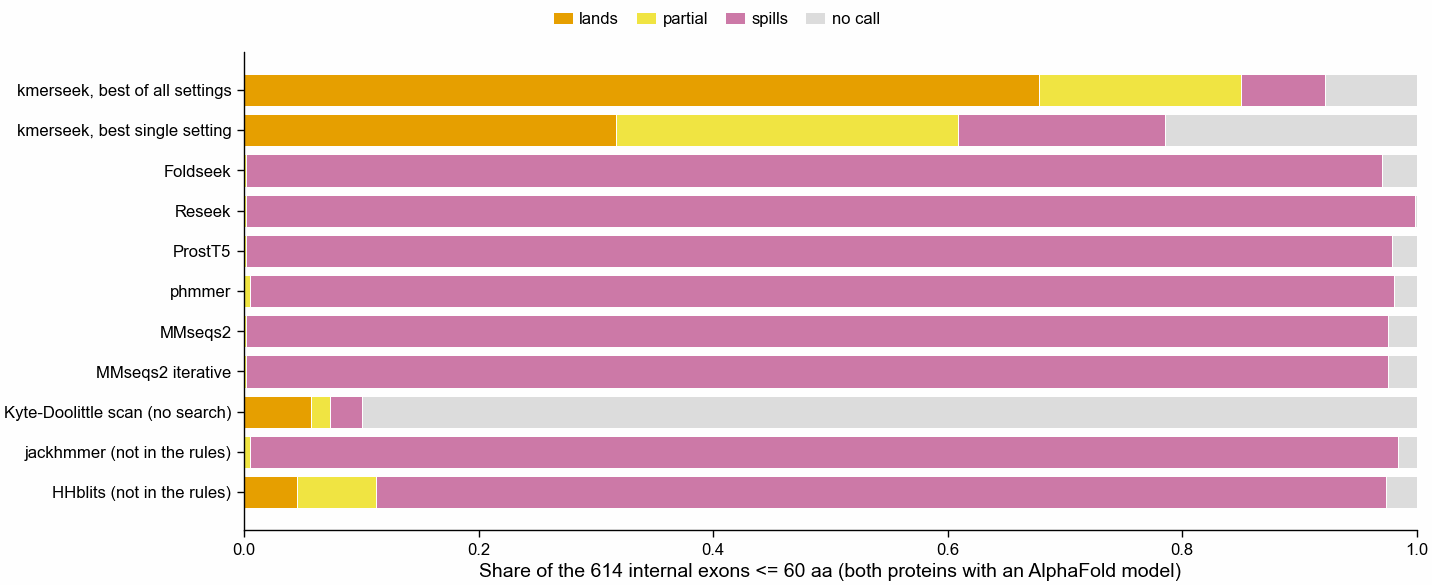

In [4]:
sf2 = el.outcome_shares(
    d, FIG / "356_sf2_outcome_shares_short_internal_exons_midi_plus"
)
print(sf2)

## 4. How tight the landing calls are (SF1)

Median IoU of the landing call, by exon-length bin, over the exons where the tool lands.
Higher is a tighter fit to the exon.

shape: (20, 5)
┌──────────────────────┬────────────┬─────┬────────────┬───────┐
│ tool                 ┆ length_bin ┆ n   ┆ median_iou ┆ x     │
│ ---                  ┆ ---        ┆ --- ┆ ---        ┆ ---   │
│ str                  ┆ str        ┆ u32 ┆ f64        ┆ f64   │
╞══════════════════════╪════════════╪═════╪════════════╪═══════╡
│ hhblits              ┆ 21-40      ┆ 11  ┆ 0.622      ┆ 35.0  │
│ hhblits              ┆ 41-60      ┆ 17  ┆ 0.457      ┆ 51.0  │
│ hhblits              ┆ 61-120     ┆ 5   ┆ 0.642      ┆ 74.0  │
│ hhblits              ┆ >120       ┆ 1   ┆ 0.555      ┆ 191.0 │
│ hmmer3_phmmer        ┆ >120       ┆ 1   ┆ 0.745      ┆ 178.0 │
│ kd_scan              ┆ 21-40      ┆ 15  ┆ 0.647      ┆ 35.0  │
│ kd_scan              ┆ 41-60      ┆ 20  ┆ 0.422      ┆ 51.0  │
│ kd_scan              ┆ 61-120     ┆ 7   ┆ 0.317      ┆ 65.0  │
│ kmerseek_best_of_all ┆ <=20       ┆ 15  ┆ 0.632      ┆ 19.0  │
│ kmerseek_best_of_all ┆ 21-40      ┆ 198 ┆ 0.635      ┆ 33.0  │
│ kmerseek

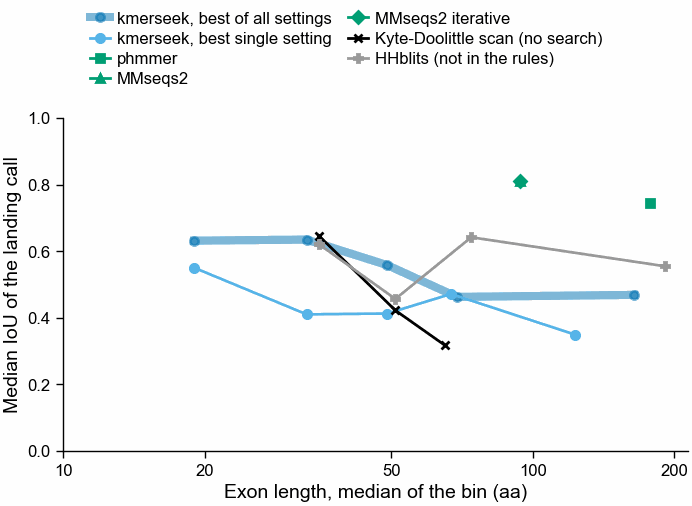

In [5]:
sf1 = el.iou_by_length(d, FIG / "356_sf1_median_iou_by_exon_length_midi_plus")
print(sf1.with_columns(pl.col("median_iou").round(3)))

## 5. Ordered against disordered exons (SF3)

Exons split by the mean AlphaFold pLDDT of their residues on the target (ordered >= 70,
disordered < 70). Structure tools are expected to do worse on disordered exons.

shape: (22, 5)
┌──────────────────────┬────────────┬─────┬─────────┬───────┐
│ tool                 ┆ disorder   ┆ n   ┆ n_lands ┆ rate  │
│ ---                  ┆ ---        ┆ --- ┆ ---     ┆ ---   │
│ str                  ┆ str        ┆ u32 ┆ u32     ┆ f64   │
╞══════════════════════╪════════════╪═════╪═════════╪═══════╡
│ foldseek             ┆ disordered ┆ 92  ┆ 0       ┆ 0.0   │
│ foldseek             ┆ ordered    ┆ 522 ┆ 0       ┆ 0.0   │
│ hhblits              ┆ disordered ┆ 92  ┆ 1       ┆ 0.011 │
│ hhblits              ┆ ordered    ┆ 522 ┆ 27      ┆ 0.052 │
│ hmmer3_jackhmmer     ┆ disordered ┆ 92  ┆ 0       ┆ 0.0   │
│ hmmer3_jackhmmer     ┆ ordered    ┆ 522 ┆ 0       ┆ 0.0   │
│ hmmer3_phmmer        ┆ disordered ┆ 92  ┆ 0       ┆ 0.0   │
│ hmmer3_phmmer        ┆ ordered    ┆ 522 ┆ 0       ┆ 0.0   │
│ kd_scan              ┆ disordered ┆ 92  ┆ 2       ┆ 0.022 │
│ kd_scan              ┆ ordered    ┆ 522 ┆ 33      ┆ 0.063 │
│ kmerseek_best_of_all ┆ disordered ┆ 92  ┆ 39      ┆ 0

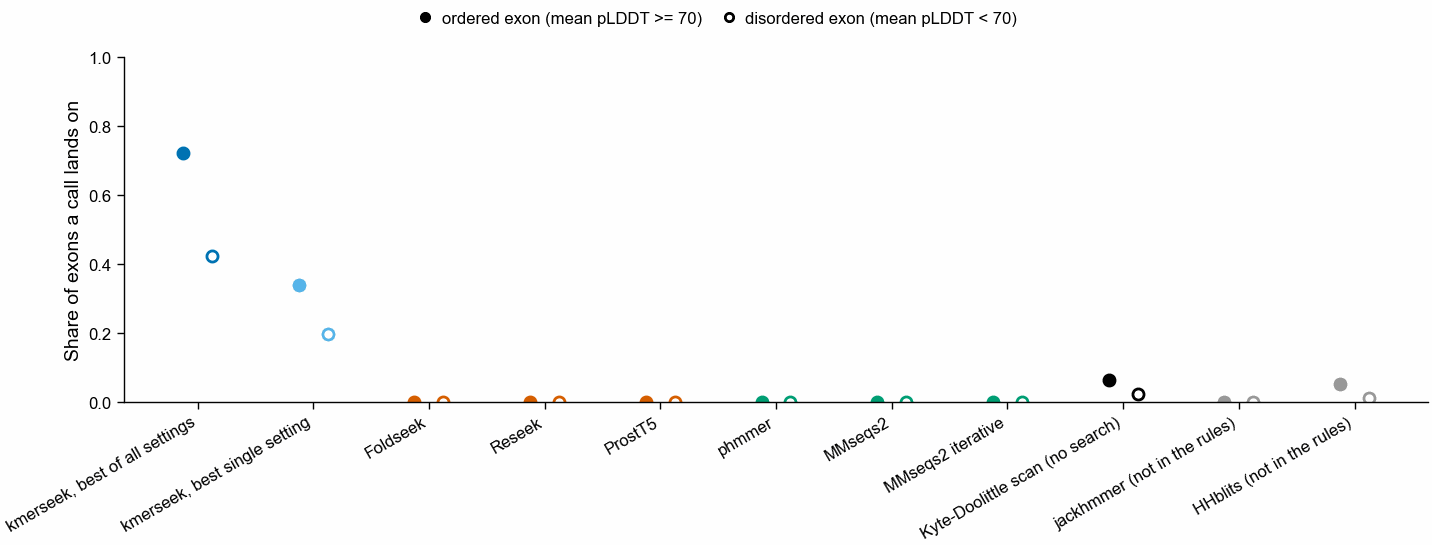

In [6]:
sf3 = el.landing_by_disorder(d, FIG / "356_sf3_landing_by_exon_disorder_midi_plus")
print(sf3.with_columns(pl.col("rate").round(3)))

## 6. kmerseek's best of all settings against chance

(a) Every kmerseek setting's landing rate on the verdict exons, with the best of all
settings as a line. (b) The same best-of-all rule scored on decoys: each exon's interval
moved, at the same coordinates, onto another pair's target protein. If the real rate sits
inside the null, landing on an exon is something kmerseek's short matches do anywhere.

shape: (3, 5)
┌─────────────────────────────────┬────────────┬─────────────┬───────────┬────────────┐
│ kmerseek number                 ┆ real exons ┆ null median ┆ null 0.1% ┆ null 99.9% │
│ ---                             ┆ ---        ┆ ---         ┆ ---       ┆ ---        │
│ str                             ┆ f64        ┆ f64         ┆ f64       ┆ f64        │
╞═════════════════════════════════╪════════════╪═════════════╪═══════════╪════════════╡
│ best of all settings            ┆ 0.678      ┆ 0.637       ┆ 0.581     ┆ 0.697      │
│ best of all, p_place < 0.05     ┆ 0.386      ┆ 0.366       ┆ 0.309     ┆ 0.426      │
│ best single setting (sdm12_k6_… ┆ 0.318      ┆ 0.28        ┆ 0.226     ┆ 0.339      │
└─────────────────────────────────┴────────────┴─────────────┴───────────┴────────────┘
shape: (10, 4)
┌─────────────────────┬────────┬─────────┬──────────┐
│ arm                 ┆ n_land ┆ n_exons ┆ rate     │
│ ---                 ┆ ---    ┆ ---     ┆ ---      │
│ str            

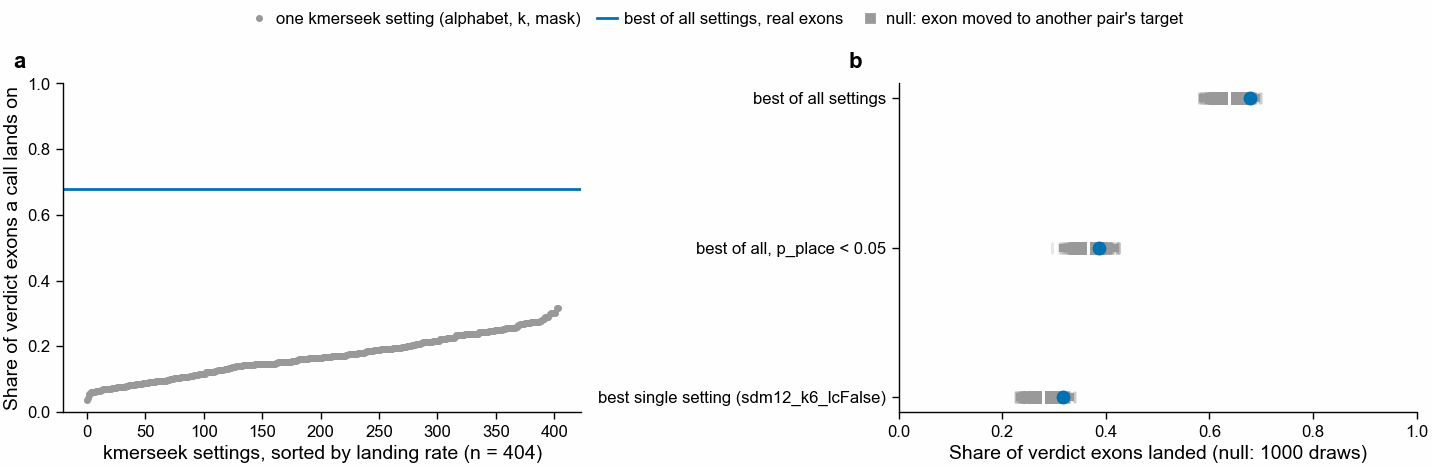

In [7]:
null_tab = el.settings_and_null(
    d, FIG / "356_kmerseek_settings_and_random_protein_null_midi_plus"
)
print(null_tab.with_columns(pl.col(pl.Float64).round(3)))
print(d["settings"].head(10))

## Summary and conclusions (Stop 0, 200-pair pilot, 2026-10-20)

**Data.** 200 of the 546 1:1 ortholog pairs, picked by the SHA-1 of the pair name. 198
of them have exon truth (72 chicken, 126 zebrafish). They hold 1,041 internal exons of
60 residues or fewer, and 614 of those are on pairs where both proteins have an AlphaFold
model (the verdict set).

**Under the pre-registered rule, the pilot passes all three parts.**

1. kmerseek's best of all 404 settings lands on 416 of 614 short exons (68%; rule: at
   least 50%).
2. Foldseek, Reseek and ProstT5 each land on 0 of 614 (rule: under 15%). Their calls
   cover most of the protein: Foldseek spills on 595 of 614 exons, Reseek on 612.
3. Counting only landing calls with a placement p-value below 0.05, kmerseek lands on
   237 of 614 (39%), 6.8 times the Kyte-Doolittle scan's 35 of 614 (6%; rule: at least
   2 times).

The Stop 0 checks do not stop the work: kmerseek lands on well over 10% of short exons,
and the scan does not reach kmerseek's rate.

**The random-protein null shows the rule does not test what it was written to test.**
When each exon's interval is moved, at the same coordinates, onto the target protein of
another pair, kmerseek still lands on it at almost the same rate (1,000 draws):

| kmerseek number | real exons | null median | null 99.9th percentile |
|---|---|---|---|
| best of all settings | 67.8% | 63.7% | 69.7% |
| best of all, p_place < 0.05 | 38.6% | 36.6% | 42.6% |
| best single setting (sdm12, k 6, no mask) | 31.8% | 28.0% | 33.9% |

All three real rates are inside their nulls. kmerseek's calls are short gapless runs
spread along both proteins. A short run that falls inside any 20-60 residue stretch
passes the landing rule (80% of the call inside, 30% of the stretch covered), whether or
not that stretch is an exon. Structure tools and aligners never land because they make
one call over most of the protein, so they are not a fair control for this; only the
null is. The placement p-value does not fix it either: it asks whether a call of that
length would land at a random position on the same protein, which a short call often
does not, so it passes calls that the null shows are not specific to exons. The null
was pre-registered for the best of all settings only; the two other rows were added
after Stop 0 and are labelled as such in `verdict.json`.

**Conclusion.** On the pilot, kmerseek's calls land on short exons as often as they
land on the same coordinates of an unrelated protein. The pilot gives no evidence that
kmerseek places a call on a single exon. The pre-registered rule passes, and that pass
should not be quoted: the rule's controls (structure tools, aligners, the scan) all make
long calls or almost no calls, so none of them measures how often a short call lands by
chance.

**Smaller points.** kmerseek lands more often on ordered exons (377 of 522, 72%) than
on disordered ones (39 of 92, 42%); the null was not split by disorder. HHblits lands on
28 of 614 and phmmer, MMseqs2 and jackhmmer on none. Reseek target positions on 4
F-digit TrEMBL accessions were past the protein end and were corrected (the known
fragment-offset bug).

**Decision for Olga.** Stop 1 (all 546 pairs) costs seconds on the laptop, since the
calls are already cut. It would tighten the numbers but cannot change the reading
unless the null and the real rates separate with more exons.